Design and implement a deep learning application for audio classification that incorporates
Speech-to-Text (STT) and Text-to-Speech (TTS) using an appropriate deep learning architecture,
and evaluate its performance using suitable metrics.

In [ ]:
%pip -q install "transformers==4.57.1" "librosa==0.11.0" "jiwer==4.0.0" soundfile scikit-learn matplotlib pandas tqdm


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 1.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 71.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 39.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 101.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 100.6 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.29.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [ ]:
import copy, json, random, re, time, zipfile, urllib.request
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa, soundfile as sf
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report, ConfusionMatrixDisplay
from tqdm.auto import tqdm
from IPython.display import Audio, display
from jiwer import wer, cer
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
OUT = Path('/content/voice_assistant_outputs'); OUT.mkdir(exist_ok=True, parents=True)
SR = 16000
print('Device:', DEVICE, '| torch:', torch.__version__)


Device: cpu | torch: 2.11.0+cpu


In [ ]:
root = Path('/content/audio_data'); root.mkdir(exist_ok=True)
archive = root / 'mini_speech_commands.zip'
if not archive.exists():
    urllib.request.urlretrieve('https://storage.googleapis.com/download.tensorflow.org/data/mini_speech_commands.zip', archive)
if not (root / 'mini_speech_commands' / 'yes').exists():
    with zipfile.ZipFile(archive) as z:
        for member in z.infolist():
            target = (root / member.filename).resolve()
            if not target.is_relative_to(root.resolve()): raise ValueError('Unsafe archive path')
        z.extractall(root)
labels = ['down','go','left','no','right','stop','up','yes']
paths = sorted(p for p in (root/'mini_speech_commands').glob('*/*.wav') if p.parent.name in labels)
y = np.array([labels.index(p.parent.name) for p in paths])
groups = np.array([p.stem.split('_nohash_')[0] for p in paths])
indices = np.arange(len(paths))
tr, held = next(GroupShuffleSplit(n_splits=1, test_size=.30, random_state=SEED).split(indices, y, groups))
va_rel, te_rel = next(GroupShuffleSplit(n_splits=1, test_size=.50, random_state=SEED).split(held, y[held], groups[held]))
va, te = held[va_rel], held[te_rel]
assert not (set(groups[tr]) & set(groups[va]) or set(groups[tr]) & set(groups[te]) or set(groups[va]) & set(groups[te]))
for split in [tr, va, te]: assert len(set(y[split])) == len(labels)
counts = pd.DataFrame({name:np.bincount(y[idx], minlength=8) for name,idx in [('train',tr),('validation',va),('test',te)]}, index=labels)
display(counts)
train_ids, val_ids = set(tr), set(va)
pd.DataFrame({'path':[str(p) for p in paths], 'label':[labels[i] for i in y], 'speaker':groups,
              'split': ['train' if i in train_ids else 'validation' if i in val_ids else 'test' for i in indices]}).to_csv(OUT/'splits.csv',index=False)


,train,validation,test
down,711,132,157
go,689,149,162
left,675,163,162
no,680,164,156
right,690,132,178
stop,714,119,167
up,696,159,145
yes,698,141,161


Spectrograms:   0%|          | 0/8000 [00:00<?, ?it/s]

Parameters: 94152


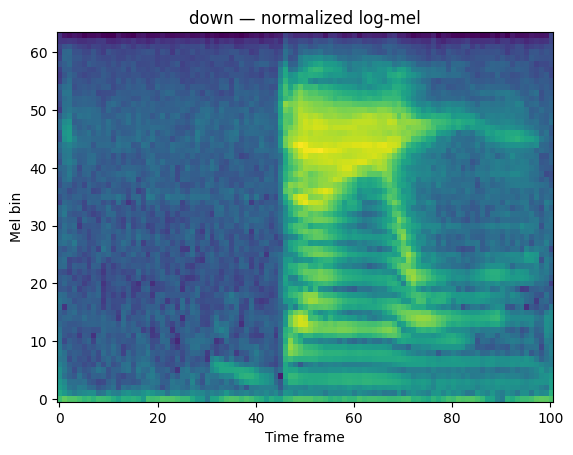

In [ ]:
def load_audio(path):
    a, sr = sf.read(str(path), dtype='float32')
    if a.ndim == 2: a = a.mean(axis=1)
    if sr != SR: a = librosa.resample(a, orig_sr=sr, target_sr=SR)
    if not len(a): raise ValueError('Empty audio')
    return np.asarray(a, dtype=np.float32)

def feature(a):
    a = librosa.util.fix_length(a, size=SR)
    mel = librosa.feature.melspectrogram(y=a, sr=SR, n_fft=400, hop_length=160, n_mels=64)
    return librosa.power_to_db(mel, ref=1.0).astype('float32')
X = np.stack([feature(load_audio(p)) for p in tqdm(paths, desc='Spectrograms')])
mean, std = float(X[tr].mean()), float(X[tr].std() + 1e-6)
X = torch.from_numpy((X-mean)/std).unsqueeze(1)
Y = torch.tensor(y, dtype=torch.long)
loaders = {name:DataLoader(TensorDataset(X[idx],Y[idx]),batch_size=64,shuffle=(name=='train'),num_workers=0)
           for name,idx in [('train',tr),('validation',va),('test',te)]}
class CommandCNN(nn.Module):
    def __init__(self):
        super().__init__()
        blocks=[]; channels=1
        for width in [32,64,128]:
            blocks += [nn.Conv2d(channels,width,3,padding=1), nn.BatchNorm2d(width), nn.ReLU(), nn.MaxPool2d(2)]
            channels=width
        self.net=nn.Sequential(*blocks, nn.AdaptiveAvgPool2d((1,1)),nn.Flatten(),nn.Dropout(.3),nn.Linear(128,8))
    def forward(self,x): return self.net(x)
model=CommandCNN().to(DEVICE)
print('Parameters:', sum(p.numel() for p in model.parameters()))
plt.imshow(X[0,0], origin='lower', aspect='auto'); plt.title(labels[y[0]]+' — normalized log-mel'); plt.xlabel('Time frame'); plt.ylabel('Mel bin'); plt.show()


Epoch 01: train loss=1.9241, val loss=1.7941, val accuracy=0.373
Epoch 02: train loss=1.6471, val loss=1.7777, val accuracy=0.304
Epoch 03: train loss=1.4172, val loss=1.4501, val accuracy=0.468
Epoch 04: train loss=1.2772, val loss=1.4267, val accuracy=0.460
Epoch 05: train loss=1.1586, val loss=1.3950, val accuracy=0.524
Epoch 06: train loss=1.0702, val loss=2.3366, val accuracy=0.269
Epoch 07: train loss=0.9767, val loss=1.0061, val accuracy=0.665
Epoch 08: train loss=0.9349, val loss=0.9658, val accuracy=0.663
Epoch 09: train loss=0.8608, val loss=1.2437, val accuracy=0.600
Epoch 10: train loss=0.8203, val loss=1.6816, val accuracy=0.463
Epoch 11: train loss=0.7975, val loss=0.8664, val accuracy=0.682
Epoch 12: train loss=0.7791, val loss=2.3270, val accuracy=0.381
Epoch 13: train loss=0.7245, val loss=1.5632, val accuracy=0.532
Epoch 14: train loss=0.6948, val loss=1.7173, val accuracy=0.509
Epoch 15: train loss=0.6719, val loss=0.9598, val accuracy=0.669
Epoch 16: train loss=0.65

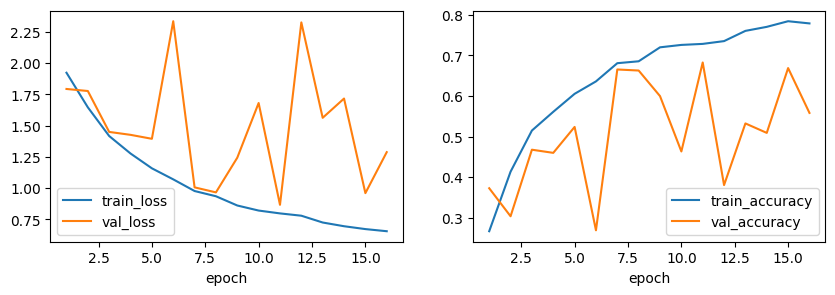

In [ ]:
optimizer=torch.optim.Adam(model.parameters(),lr=1e-3,weight_decay=1e-4)
criterion=nn.CrossEntropyLoss()
def run_epoch(loader, training=False):
    model.train(training); total_loss=0.; gold=[]; pred=[]
    with torch.set_grad_enabled(training):
        for xb,yb in loader:
            xb,yb=xb.to(DEVICE),yb.to(DEVICE)
            logits=model(xb); loss=criterion(logits,yb)
            if training:
                optimizer.zero_grad(); loss.backward(); optimizer.step()
            total_loss += loss.item()*len(yb)
            gold.extend(yb.cpu().tolist()); pred.extend(logits.argmax(1).cpu().tolist())
    return total_loss/len(gold), accuracy_score(gold,pred), gold,pred
EPOCHS=20
best_loss=float('inf'); stale=0; history=[]
for epoch in range(EPOCHS):
    tl,ta,_,_=run_epoch(loaders['train'],True)
    vl,vacc,_,_=run_epoch(loaders['validation'])
    history.append(dict(epoch=epoch+1,train_loss=tl,val_loss=vl,train_accuracy=ta,val_accuracy=vacc))
    print(f'Epoch {epoch+1:02}: train loss={tl:.4f}, val loss={vl:.4f}, val accuracy={vacc:.3f}')
    if vl < best_loss:
        best_loss=vl; best_state=copy.deepcopy(model.state_dict()); stale=0
    else: stale+=1
    if stale>=5: break
model.load_state_dict(best_state); model.eval()
history=pd.DataFrame(history); history.to_csv(OUT/'training_history.csv',index=False)
fig,ax=plt.subplots(1,2,figsize=(10,3))
history.plot(x='epoch',y=['train_loss','val_loss'],ax=ax[0]); history.plot(x='epoch',y=['train_accuracy','val_accuracy'],ax=ax[1]); plt.show()
torch.save({'model_state':{k:v.cpu() for k,v in best_state.items()},'labels':labels,'mean':mean,'std':std,'sample_rate':SR},OUT/'command_cnn.pt')


,accuracy,macro_precision,macro_recall,macro_f1,test_loss,majority_baseline_accuracy
0,0.685559,0.762643,0.690464,0.682622,0.904581,0.129658


              precision    recall  f1-score   support

        down       0.97      0.38      0.55       157
          go       0.56      0.70      0.62       162
        left       0.76      0.57      0.65       162
          no       0.48      0.94      0.63       156
       right       0.98      0.59      0.74       178
        stop       0.97      0.56      0.71       167
          up       0.68      0.92      0.78       145
         yes       0.70      0.86      0.77       161

    accuracy                           0.69      1288
   macro avg       0.76      0.69      0.68      1288
weighted avg       0.77      0.69      0.68      1288



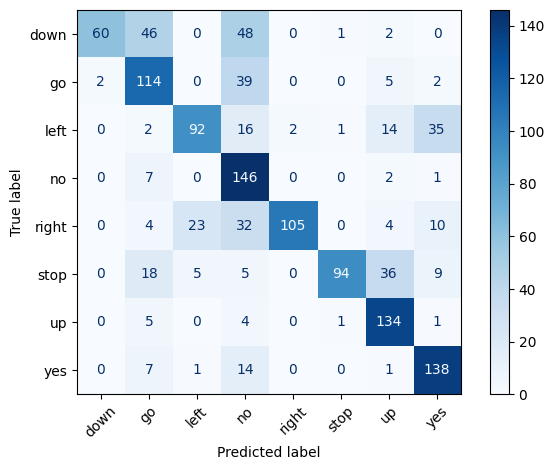

In [ ]:
test_loss,test_acc,gold,pred=run_epoch(loaders['test'])
p,r,f,_=precision_recall_fscore_support(gold,pred,average='macro',zero_division=0)
majority=int(np.bincount(y[tr]).argmax())
classification_metrics={'accuracy':test_acc,'macro_precision':p,'macro_recall':r,'macro_f1':f,
                        'test_loss':test_loss,'majority_baseline_accuracy':float(np.mean(y[te]==majority))}
display(pd.DataFrame([classification_metrics]))
print(classification_report(gold,pred,labels=list(range(8)),target_names=labels,zero_division=0))
ConfusionMatrixDisplay.from_predictions(gold,pred,labels=list(range(8)),display_labels=labels,cmap='Blues',xticks_rotation=45)
plt.tight_layout(); plt.savefig(OUT/'confusion_matrix.png'); plt.show()


In [ ]:
from transformers import pipeline, VitsModel, AutoTokenizer
asr = pipeline('automatic-speech-recognition',model='openai/whisper-tiny.en',device=0 if DEVICE.type=='cuda' else -1)
tts_tokenizer=AutoTokenizer.from_pretrained('facebook/mms-tts-eng')
tts_model=VitsModel.from_pretrained('facebook/mms-tts-eng').to(DEVICE).eval()
TTS_SR=tts_model.config.sampling_rate

def sync():
    if DEVICE.type=='cuda': torch.cuda.synchronize()

def transcribe(a):
    return asr({'raw':np.asarray(a,dtype=np.float32),'sampling_rate':SR},generate_kwargs={'do_sample':False})['text'].strip()

@torch.inference_mode()
def synthesize(text):
    inputs=tts_tokenizer(text,return_tensors='pt').to(DEVICE)
    return tts_model(**inputs).waveform[0].float().cpu().numpy()

def normalize(text): return re.sub(r'[^a-z0-9 ]','',text.lower()).strip()
# Warm up both networks before measuring inference speed.
_ = transcribe(load_audio(paths[tr[0]]))
_ = synthesize('The assistant is ready.')


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/151M [00:00<?, ?B/s]

generation_config.json: 0.00B [00:00, ?B/s]

tokenizer_config.json:   0%|          | 0.00/805 [00:00<?, ?B/s]

...

vocab.json:   0%|          | 0.00/413 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/47.0 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/145M [00:00<?, ?B/s]

`return_token_timestamps` is deprecated for WhisperFeatureExtractor and will be removed in Transformers v5. Use `return_attention_mask` instead, as the number of frames can be inferred from it.
Using custom `forced_decoder_ids` from the (generation) config. This is deprecated in favor of the `task` and `language` flags/config options.


In [ ]:
rng=np.random.default_rng(SEED)
asr_indices=np.concatenate([rng.choice(te[y[te]==k],size=min(20,sum(y[te]==k)),replace=False) for k in range(8)])
rows=[]
for i in tqdm(asr_indices,desc='STT evaluation'):
    a=load_audio(paths[i]); sync(); start=time.perf_counter()
    hypothesis=transcribe(a); sync(); elapsed=time.perf_counter()-start
    rows.append({'path':str(paths[i]),'reference':labels[y[i]],'hypothesis':normalize(hypothesis),
                 'seconds':len(a)/SR,'inference_seconds':elapsed})
asr_results=pd.DataFrame(rows)
refs=asr_results.reference.tolist(); hyps=asr_results.hypothesis.tolist()
stt_metrics={'wer':wer(refs,hyps),'cer':cer(refs,hyps),'exact_match':float(np.mean(np.array(refs)==np.array(hyps))),
             'rtf':float(asr_results.inference_seconds.sum()/asr_results.seconds.sum()),'n_clips':len(rows)}
display(pd.DataFrame([stt_metrics])); display(asr_results.head(10))
asr_results.to_csv(OUT/'stt_predictions.csv',index=False)


STT evaluation:   0%|          | 0/160 [00:00<?, ?it/s]

,wer,cer,exact_match,rtf,n_clips
0,1.56875,2.294231,0.8375,2.152488,160


,path,reference,hypothesis,seconds,inference_seconds
0,/content/audio_data/mini_speech_commands/down/...,down,down,1.0,2.819417
1,/content/audio_data/mini_speech_commands/down/...,down,down,1.0,3.363684
2,/content/audio_data/mini_speech_commands/down/...,down,down,1.0,2.089857
3,/content/audio_data/mini_speech_commands/down/...,down,down,1.0,4.673982
4,/content/audio_data/mini_speech_commands/down/...,down,dont,1.0,1.686185
5,/content/audio_data/mini_speech_commands/down/...,down,dont,1.0,1.400975
6,/content/audio_data/mini_speech_commands/down/...,down,damn,1.0,1.793075
7,/content/audio_data/mini_speech_commands/down/...,down,down,1.0,1.434736
8,/content/audio_data/mini_speech_commands/down/...,down,down,1.0,1.185401
9,/content/audio_data/mini_speech_commands/down/...,down,damn,1.0,1.234776


In [ ]:
phrases=['The predicted command is stop.', 'Please move to the left.', 'The audio classifier is ready.',
         'Turn right and then go up.', 'Say yes to confirm the command.']
tts_rows=[]
for i,text in enumerate(tqdm(phrases,desc='TTS evaluation')):
    sync(); start=time.perf_counter(); wave=synthesize(text); sync(); elapsed=time.perf_counter()-start
    sf.write(OUT/f'tts_{i}.wav',wave,TTS_SR)
    a=librosa.resample(wave,orig_sr=TTS_SR,target_sr=SR) if TTS_SR!=SR else wave
    hypothesis=transcribe(a)
    tts_rows.append({'text':text,'reference':normalize(text),'hypothesis':normalize(hypothesis),
                     'seconds':len(wave)/TTS_SR,'synthesis_seconds':elapsed})
tts_results=pd.DataFrame(tts_rows)
tts_metrics={'roundtrip_wer':wer(tts_results.reference.tolist(),tts_results.hypothesis.tolist()),
             'roundtrip_cer':cer(tts_results.reference.tolist(),tts_results.hypothesis.tolist()),
             'rtf':float(tts_results.synthesis_seconds.sum()/tts_results.seconds.sum()),'n_sentences':len(phrases)}
display(pd.DataFrame([tts_metrics])); display(tts_results)
display(Audio(filename=str(OUT/'tts_0.wav')))
tts_results.to_csv(OUT/'tts_results.csv',index=False)
pd.DataFrame([{'sentence':s,'listener_id':'','naturalness_1_to_5':'','intelligibility_1_to_5':''} for s in phrases]).to_csv(OUT/'listening_ratings_template.csv',index=False)


TTS evaluation:   0%|          | 0/5 [00:00<?, ?it/s]

,roundtrip_wer,roundtrip_cer,rtf,n_sentences
0,0.037037,0.022059,1.23681,5


,text,reference,hypothesis,seconds,synthesis_seconds
0,The predicted command is stop.,the predicted command is stop,the predicted command is stopped,2.592,6.008111
1,Please move to the left.,please move to the left,please move to the left,2.144,2.472378
2,The audio classifier is ready.,the audio classifier is ready,the audio classifier is ready,2.448,2.532472
3,Turn right and then go up.,turn right and then go up,turn right and then go up,1.872,1.528589
4,Say yes to confirm the command.,say yes to confirm the command,say yes to confirm the command,3.104,2.498062


In [ ]:
@torch.inference_mode()
def voice_assistant(path):
    a=load_audio(path)
    feat=torch.from_numpy((feature(a)-mean)/std)[None,None].to(DEVICE)
    probabilities=model(feat).softmax(1)[0].cpu().numpy()
    k=int(probabilities.argmax()); transcript=transcribe(a)
    reply=f'The predicted command is {labels[k]}.'
    wave=synthesize(reply)
    sf.write(OUT/'assistant_reply.wav',wave,TTS_SR)
    result={'command':labels[k],'softmax_score':float(probabilities[k]),'transcript':transcript,'reply':reply}
    display(pd.DataFrame([result])); display(Audio(a,rate=SR)); display(Audio(wave,rate=TTS_SR))
    return result
USE_UPLOAD=False
if USE_UPLOAD:
    from google.colab import files
    uploaded=files.upload()
    input_path=next(iter(uploaded))
else:
    input_path=paths[te[0]]
result=voice_assistant(input_path)


,command,softmax_score,transcript,reply
0,no,0.742021,Down.,The predicted command is no.


In [ ]:
summary={'classification':classification_metrics,'stt':stt_metrics,'tts':tts_metrics,
         'device':str(DEVICE),'seed':SEED,'note':'Custom speaker-disjoint split. STT/TTS pretrained; no perceptual MOS collected.'}
(OUT/'metrics.json').write_text(json.dumps(summary,indent=2))
print('Outputs:',OUT)
display(pd.json_normalize(summary))


Outputs: /content/voice_assistant_outputs


,device,seed,note,classification.accuracy,classification.macro_precision,classification.macro_recall,classification.macro_f1,classification.test_loss,classification.majority_baseline_accuracy,stt.wer,stt.cer,stt.exact_match,stt.rtf,stt.n_clips,tts.roundtrip_wer,tts.roundtrip_cer,tts.rtf,tts.n_sentences
0,cpu,42,Custom speaker-disjoint split. STT/TTS pretrai...,0.685559,0.762643,0.690464,0.682622,0.904581,0.129658,1.56875,2.294231,0.8375,2.152488,160,0.037037,0.022059,1.23681,5
